# Variable distributions & missingness — treatment and diagnosis variables

Reconstructs the pre-imputation cohort using the same preprocessing steps as `new_data.ipynb`
(stopped right before any imputation), then:

1. Reports missingness for every diagnosis variable (one summary). Treatment variables are excluded from missingness reporting entirely — they're 0-filled, not statistically imputed.
2. Shows the pre-imputation distribution of **diagnosis** variables: summary statistics (median/std/max/min/... plus % missing) for numerical variables, and one row per categorical variable with each observed value written as `value (%)` in a positional column, plus a `Missing` column (percentage only), always last.
3. Loads the final `data.csv` (post-imputation) and compares it against the pre-imputation distributions for the variables that go through *statistical* imputation (mode-imputed categoricals, median-imputed numericals).
4. Shows the post-transform distribution (without a pre/post framing) for the ER/PR/HER2 missing-indicator variables and the **treatment** variables — the same table format as (2), but computed on the fully-preprocessed `final_dataset` and without a `Missing` column, since treatment variables are 0-filled ("not administered") rather than statistically imputed.

The missingness summary chart plus the Ki67/Age pre-vs-post figures are intended for the main text;
everything else is meant for the appendix.

In [125]:
import sys
import os
sys.path.append(os.path.abspath('../../../'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from functions.preproc import *
from scipy.stats import skew, shapiro

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

# Thesis palette (matches graphs_andmore.ipynb)
NAVY = '#1E3A8A'
TEAL = '#0D9488'
ROSE = '#E11D48'
SLATE = '#0F172A'
MUTED = '#64748B'
GRID_COLOR = '#E2E8F0'

plt.rcParams.update({
    'font.family': 'sans-serif',
    'text.color': SLATE,
    'axes.labelcolor': SLATE,
    'xtick.color': MUTED,
    'ytick.color': SLATE,
})

OUTPUT_DIR = 'distributions'
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 1. Cohort setup (pre-imputation)

Same steps as `new_data.ipynb`: load the raw extract, fix the known column typo, derive `Date of diagnosis`/`Survival days`, filter to EBC, cast types, and apply the same value remappings. We stop **before** `fill_with_mode`, `one_hot_encode_with_missing_indicator`, `median_imputer`, and `one_hot_encoding` — so all missingness in this section is the real, untouched missingness of the cohort.

In [126]:
dataset = pd.read_excel('../../../BreastCareCond.xlsx')
data_code = pd.read_excel('../../../Codificação variaveis.xlsx')

relevant_variables = ['PERSON_ID', 'Regional LN recurrence', 'Date of 1st regional recurrence', 'EBC', 'Survival days']

diagnosis_numerical = ['Age', 'Ki67 positive cells (%) at CB']
diagnosis_categorical = ['Grade at CB', 'Side location of the lesion',
                          'Type of invasion at CB', 'Isotype at CB',
                          'Oestrogen receptor status at CB', 'Progesterone receptor status at CB',
                          'Her2 overexpression (with immunohystochemistry) at CB',
                          'N (Regional nodes affected)']

date_columns = ['Date of CB ', 'Date of 1st breast operation', 'Date of intervention on sentinel lymph node',
                'Date of intervention (axilla)']

In [127]:
#correcting the error in the column name
dataset.rename(columns={'Istotype at CB': 'Isotype at CB'}, inplace=True)

dataset = date_of_diagnosis(dataset, date_columns)

relevant_dates = ['Date of diagnosis', 'Date of 1st regional recurrence']
dataset = remove_zeros_na(dataset, relevant_dates)
dataset = format_date(dataset, relevant_dates)

dataset = survival_days(dataset, ['Date of diagnosis'], ['Date of 1st regional recurrence'])
dataset = tte_negative_patients(dataset)
dataset = filter_EBC(dataset)
dataset.reset_index(drop=True, inplace=True)

change_to_numeric(dataset, diagnosis_numerical)
change_to_categorical(dataset, diagnosis_categorical)

Done
Done


In [128]:
# Same value remapping as new_data.ipynb, applied before imputation
columns_to_map = {
    'Side location of the lesion': {'L': 0, 'R': 1},
    'Type of invasion at CB': {1: 0, 2: 1},
    'Oestrogen receptor status at CB': {1: 0, 2: 1},
    'Progesterone receptor status at CB': {1: 0, 2: 1},
    'N (Regional nodes affected)': {0: 0, 1: 1, 2: 2_3, 3: 2_3},
}

for column, mapping in columns_to_map.items():
    dataset[column] = dataset[column].map(mapping)

> **Note on `N (Regional nodes affected)`**: the mapping above is copied as-is from `new_data.ipynb`.
> `2_3` is a Python numeric literal (underscore digit separator) equal to `23`, not the string `"2-3"` the
> name suggests — so N=2 and N=3 are both collapsed into a category labelled `23` in `data.csv`
> (see `N (Regional nodes affected)_23.0`). This is a pre-existing quirk of the pipeline, reproduced
> here faithfully rather than corrected, since fixing it would change the modelling pipeline's output —
> flagging it here since it's visible in the distribution plots below.

In [129]:
# Deduplicate patients with recurrence (same logic as new_data.ipynb): keep only the first row
# for a PERSON_ID that appears more than once with Regional LN recurrence == 1.
mask = (dataset.duplicated(subset='PERSON_ID', keep=False) & (dataset['Regional LN recurrence'] == 1))

to_remove = (
    dataset[mask]
    .groupby('PERSON_ID')
    .tail(-1)
    .index
)

dataset = dataset.drop(to_remove)
dataset.reset_index(drop=True, inplace=True)

In [130]:
# Treatment variables — raw column names, split into numerical/categorical via the codification sheet
treatment_variables_raw = ['Radiotherapy (RT) performed', 'Conventional RT fraction', 'Total administered dose', 'Boost dose administered',
                            'Radiotherapy on chest wall', 'Radiotherapy on supraclavicular area', 'Radiotherapy on internal mammary chain',
                            'State (if hormone therapy prescribed)', 'Treatment in association with chemotherapy',
                            'Chemotherapy performed', 'Adjuvant chemotherapy', 'Adjuvant therapy with biological drugs',
                            'Endocrine therapy performed']

treatment_numerical, treatment_categorical = type_separation(data_code, treatment_variables_raw)
len(treatment_numerical), len(treatment_categorical)

(3, 10)

In [131]:
# Create a derived neoadjuvant therapy only variable, right at the start so it's used
# consistently in both the pre-transform and post-transform sections below.
# It is 1 when adjuvant therapy with biological drugs is 0 and endocrine therapy performed is 1.
dataset['Adjuvant therapy using biological drugs'] = dataset['Adjuvant therapy with biological drugs'].apply(
    lambda x: 1 if x in [1, 2] else 0
)
dataset['Neoadjuvant (Only) therapy with biological drugs'] = (
    (dataset['Adjuvant therapy using biological drugs'] == 0) &
    (dataset['Endocrine therapy performed'] == 1)
).astype(int)

treatment_categorical = [col for col in treatment_categorical if col != 'Endocrine therapy performed']
treatment_categorical.append('Neoadjuvant (Only) therapy with biological drugs')

## 2. Missingness summary — diagnosis variables

Treatment variables are intentionally left out here (and everywhere else missingness is reported): they're 0-filled ("not administered") rather than statistically imputed, so their missingness isn't part of this analysis — see Section 4 for their post-preprocessing distribution instead.

In [132]:
missingness_table = missing_values(dataset, diagnosis_numerical + diagnosis_categorical)
missingness_table = missingness_table.sort_values('Percentage Missing', ascending=False).reset_index(drop=True)
missingness_table

,Column,Missing Values,Percentage Missing
0,Ki67 positive cells (%) at CB,536,16.604709
1,Her2 overexpression (with immunohystochemistry) at CB,475,14.714994
2,Progesterone receptor status at CB,445,13.785626
3,Grade at CB,194,6.009913
4,Isotype at CB,142,4.399009
5,Type of invasion at CB,141,4.368030
6,Oestrogen receptor status at CB,136,4.213135
7,Side location of the lesion,14,0.433705
8,N (Regional nodes affected),13,0.402726
9,Age,0,0.000000


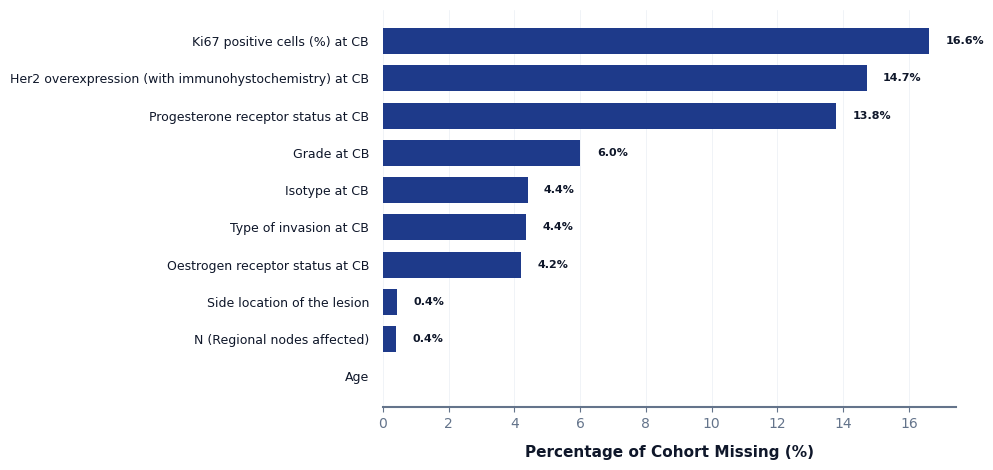

In [133]:
plot_table = missingness_table.sort_values('Percentage Missing', ascending=True).copy()

fig, ax = plt.subplots(figsize=(10, 0.28 * len(plot_table) + 2), facecolor='none')
ax.set_facecolor('none')

bars = ax.barh(plot_table['Column'], plot_table['Percentage Missing'], color=NAVY, height=0.7, edgecolor='none')

ax.set_xlabel('Percentage of Cohort Missing (%)', fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel('')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_linewidth(1.5)
ax.spines['bottom'].set_color(MUTED)

ax.grid(axis='x', color=GRID_COLOR, linestyle='-', linewidth=0.5, alpha=0.7)
ax.set_axisbelow(True)

ax.tick_params(axis='y', length=0, labelsize=9, pad=10)
ax.tick_params(axis='x', labelsize=10, color=MUTED)

for bar in bars:
    width = bar.get_width()
    if width > 0.1:
        ax.text(width + 0.5, bar.get_y() + bar.get_height() / 2, f'{width:.1f}%',
                va='center', fontsize=8, fontweight='bold', color=SLATE)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'missingness_summary.png'), dpi=300, transparent=True, bbox_inches='tight')
plt.show()

## 3. Pre-imputation distributions — diagnosis variables (appendix)

Numerical variables: summary statistics table (median/std/max/min/... plus % missing). Categorical variables: one row per variable, each observed value shown as `value (%)` in a positional column, `Missing` (percentage only) always last. Treatment variables are covered in Section 4 instead, on the fully-preprocessed data (no missingness left to show once 0-filled). These are what justify each variable's imputation strategy (e.g. skewness driving median over mean for Ki67).

In [134]:
display(test_normality(dataset, diagnosis_numerical + treatment_numerical))

,Variable,Skewness,Shapiro p-value,Normality,Has Outliers
0,Age,0.241012,6.932576e-17,Probably not normal,False
1,Ki67 positive cells (%) at CB,0.990519,6.725040e-39,Probably not normal,True
2,Conventional RT fraction,11.551951,9.494862e-74,Probably not normal,True
3,Total administered dose,-2.029055,1.608351e-66,Probably not normal,True
4,Boost dose administered,22.660866,5.319402e-73,Probably not normal,True


In [ ]:
def canon_category(x):
    """Canonical string label for a category value, so '0', 0, and 0.0 all compare equal."""
    if pd.isna(x):
        return np.nan
    try:
        f = float(x)
        return str(int(f)) if f.is_integer() else str(f)
    except (TypeError, ValueError):
        return str(x)

def to_display_categories(series):
    return series.map(canon_category)

def sort_categories(categories):
    def key(c):
        if c == 'Missing':
            return (2, 0.0, '')
        try:
            return (0, float(c), '')
        except ValueError:
            return (1, 0.0, c)
    return sorted(categories, key=key)

def categorical_distribution_wide(dataset, variables, include_missing=True):
    """One row per variable. Each observed category becomes a cell 'value (pct%)' placed in a
    generic, positional 'Value N' column (columns aren't tied to a specific code, since the same
    code means different things for different variables) — the value itself is written inside the
    cell instead of being used as a column header. 'Missing' is its own trailing column showing
    just the percentage, when include_missing=True."""
    total = len(dataset)
    rows = []
    max_categories = 0
    for column in variables:
        cats = to_display_categories(dataset[column])
        counts = cats.value_counts(dropna=True)
        ordered = sort_categories(counts.index.tolist())
        max_categories = max(max_categories, len(ordered))

        row = {'Variable': column}
        for i, category in enumerate(ordered):
            row[f'Value {i + 1}'] = f"{category} ({100 * counts[category] / total:.1f}%)"
        if include_missing:
            n_missing = int(cats.isna().sum())
            row['Missing'] = f"{100 * n_missing / total:.1f}%"
        rows.append(row)

    value_cols = [f'Value {i + 1}' for i in range(max_categories)]
    ordered_cols = ['Variable'] + value_cols + (['Missing'] if include_missing else [])
    return pd.DataFrame(rows).reindex(columns=ordered_cols).set_index('Variable').fillna('—')

def numerical_stats_with_missing(dataset, variables):
    """numerical_descriptive_statistics(), with a 'Missing %' column prepended."""
    stats = numerical_descriptive_statistics(dataset, variables)
    total = len(dataset)
    stats.insert(0, 'Missing %', [round(100 * dataset[v].isna().sum() / total, 1) for v in stats.index])
    return stats

def numerical_stats_with_performed(dataset, variables):
    """Descriptive statistics restricted to recipients only: for each variable, Mean/Median/Sd/Max/
    percentiles are computed on the non-zero values (value != 0) rather than the full 0-filled
    cohort, since 0 means "not administered". A leading 'Performed' column reports the count/pct
    of patients with a non-zero value."""
    total = len(dataset)
    performed = []
    per_var_stats = []
    for v in variables:
        non_zero = dataset[dataset[v] != 0][[v]]
        n = len(non_zero)
        performed.append(f"{n} ({100 * n / total:.1f}%)")
        per_var_stats.append(numerical_descriptive_statistics(non_zero, [v]))
    stats = pd.concat(per_var_stats)
    stats.insert(0, 'Performed', performed)
    return stats

### Diagnosis variables — pre-imputation

One row per variable; each cell is `value (%)` for an observed category (columns are positional, not tied to a specific code), with `Missing` (percentage only) always the last column.

In [136]:
display(numerical_stats_with_missing(dataset, diagnosis_numerical))
display(categorical_distribution_wide(dataset, diagnosis_categorical, include_missing=True))

,Missing %,Counts,Mean,Median,Sd,Max,Min,25th,50th,75th
Age,0.0,3228,55.193309,54.0,12.496636,89.0,20.0,46.0,54.0,65.0
Ki67 positive cells (%) at CB,16.6,2692,31.682764,25.0,22.551012,100.0,0.0,15.0,25.0,40.0


,Value 1,Value 2,Value 3,Value 4,Missing
Variable,,,,,
Grade at CB,1 (14.7%),2 (57.9%),3 (21.3%),—,6.0%
Side location of the lesion,0 (51.9%),1 (47.7%),—,—,0.4%
Type of invasion at CB,0 (10.0%),1 (85.6%),—,—,4.4%
Isotype at CB,1 (66.3%),2 (11.1%),3 (1.3%),4 (16.9%),4.4%
Oestrogen receptor status at CB,0 (13.7%),1 (82.1%),—,—,4.2%
Progesterone receptor status at CB,0 (20.6%),1 (65.6%),—,—,13.8%
Her2 overexpression (with immunohystochemistry) at CB,1 (63.3%),2 (12.5%),3 (9.5%),—,14.7%
N (Regional nodes affected),0 (75.4%),1 (21.6%),23 (2.6%),—,0.4%


## 4. Post-imputation / post-transform comparison (appendix)

Loads the final `data.csv` (already mode/median-imputed and one-hot encoded) and, for the variables that underwent **statistical imputation**, compares the pre- and post-imputation distributions side by side — a sanity check that imputation didn't distort the shape. One-hot columns are collapsed back to a single category so the comparison lines up with the pre-imputation variable.

In [137]:
final_dataset = pd.read_csv('../data.csv', index_col=0)

with open('../diagnosis.txt') as f:
    diagnosis_final_variables = [line.strip() for line in f if line.strip()]
with open('../treatment.txt') as f:
    treatment_final_variables = [line.strip() for line in f if line.strip()]

def get_post_series(final_dataset, variable):
    """Return the post-imputation category for `variable`, collapsing one-hot columns back to a
    single label and using 'Missing' for rows where the (one-hot) missing-indicator category applies."""
    if variable in final_dataset.columns:
        return to_display_categories(final_dataset[variable])

    prefix_cols = sorted(c for c in final_dataset.columns if c.startswith(variable + '_'))
    if not prefix_cols:
        raise ValueError(f'No post-imputation column(s) found for {variable!r}')

    sub = final_dataset[prefix_cols]
    is_missing = sub.sum(axis=1) == 0
    raw_labels = sub.idxmax(axis=1).str.replace(variable + '_', '', regex=False)
    labels = raw_labels.map(canon_category)
    return labels.mask(is_missing, 'Missing')

In [138]:
def plot_numeric_pre_post(dataset, final_dataset, variables, title, filename, cols=2):
    if not variables:
        return None
    rows = int(np.ceil(len(variables) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(7 * cols, 4.2 * rows), facecolor='none', squeeze=False)
    axes = axes.flatten()

    for ax, variable in zip(axes, variables):
        ax.set_facecolor('none')
        pre = dataset[variable].dropna().astype(float)
        post = final_dataset[variable].astype(float)
        bins = np.histogram_bin_edges(post, bins='auto')

        ax.hist(pre, bins=bins, color=MUTED, alpha=0.6, density=True, label='Pre-imputation (observed only)')
        ax.hist(post, bins=bins, color=TEAL, alpha=0.6, density=True, label='Post-imputation (full cohort)')
        ax.axvline(pre.median(), color=SLATE, linestyle='--', linewidth=1.2)
        ax.axvline(post.median(), color=ROSE, linestyle='--', linewidth=1.2)

        n_missing = dataset[variable].isna().sum()
        ax.set_title(f'{variable}\n(imputed n={n_missing})', fontsize=10)
        ax.set_xlabel('Value')
        ax.set_ylabel('Density')
        ax.legend(fontsize=8, frameon=False)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    for ax in axes[len(variables):]:
        ax.axis('off')

    fig.suptitle(title, fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=200, transparent=True, bbox_inches='tight')
    plt.show()
    return fig

def plot_categorical_pre_post(dataset, final_dataset, variables, title, filename, cols=2):
    if not variables:
        return None
    rows = int(np.ceil(len(variables) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(7 * cols, 4.2 * rows), facecolor='none', squeeze=False)
    axes = axes.flatten()

    for ax, variable in zip(axes, variables):
        ax.set_facecolor('none')
        pre = to_display_categories(dataset[variable]).dropna()
        pre_counts = pre.value_counts(normalize=True) * 100

        post = get_post_series(final_dataset, variable)
        post = post[post != 'Missing']
        post_counts = post.value_counts(normalize=True) * 100

        categories = sort_categories(set(pre_counts.index) | set(post_counts.index))
        x = np.arange(len(categories))
        width = 0.35
        pre_vals = [pre_counts.get(c, 0) for c in categories]
        post_vals = [post_counts.get(c, 0) for c in categories]

        ax.bar(x - width / 2, pre_vals, width, color=MUTED, edgecolor='white', label='Pre-imputation')
        ax.bar(x + width / 2, post_vals, width, color=TEAL, edgecolor='white', label='Post-imputation')
        ax.set_xticks(x)
        ax.set_xticklabels(categories, fontsize=9)

        n_missing = dataset[variable].isna().sum()
        ax.set_title(f'{variable}\n(imputed n={n_missing})', fontsize=10)
        ax.set_ylabel('% of observed patients')
        ax.legend(fontsize=8, frameon=False)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    for ax in axes[len(variables):]:
        ax.axis('off')

    fig.suptitle(title, fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=200, transparent=True, bbox_inches='tight')
    plt.show()
    return fig

### Median-imputed numerical variables (main text: Ki67)

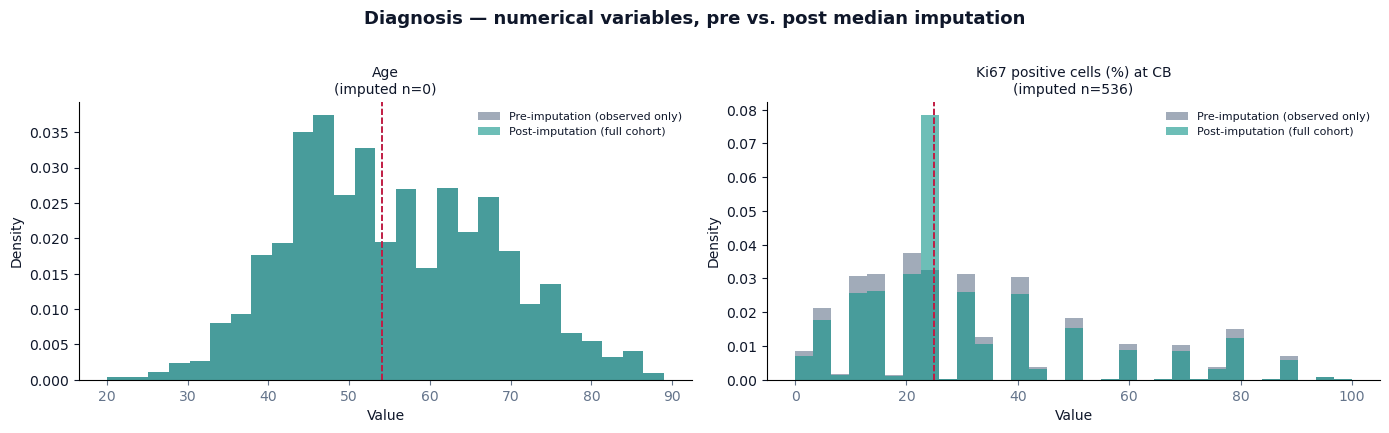

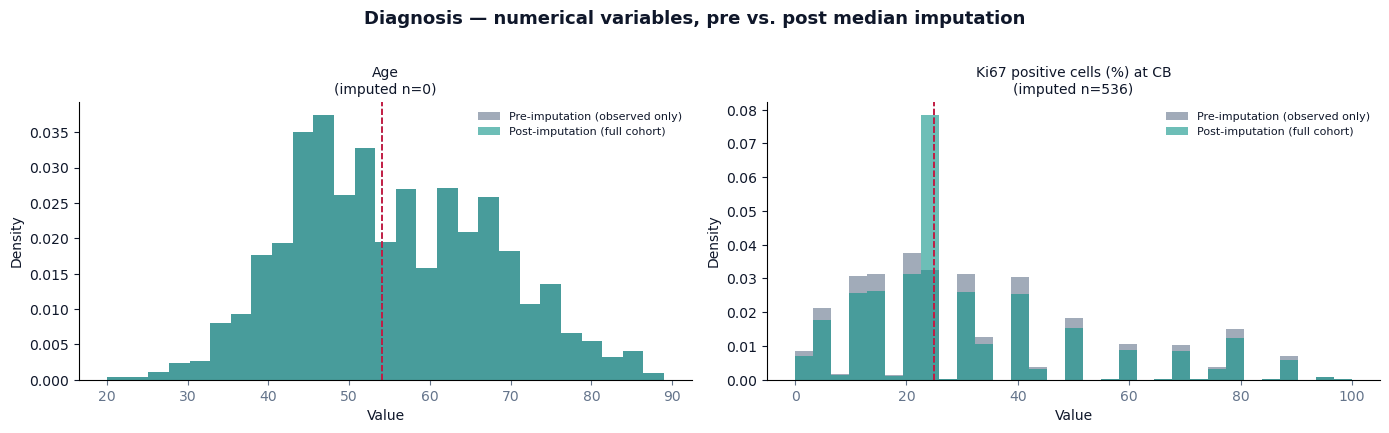

In [139]:
median_imputed_numerical = ['Age', 'Ki67 positive cells (%) at CB']
plot_numeric_pre_post(dataset, final_dataset, median_imputed_numerical,
                       'Diagnosis — numerical variables, pre vs. post median imputation',
                       'diagnosis_numerical_pre_post.png', cols=2)

### Mode-imputed categorical variables

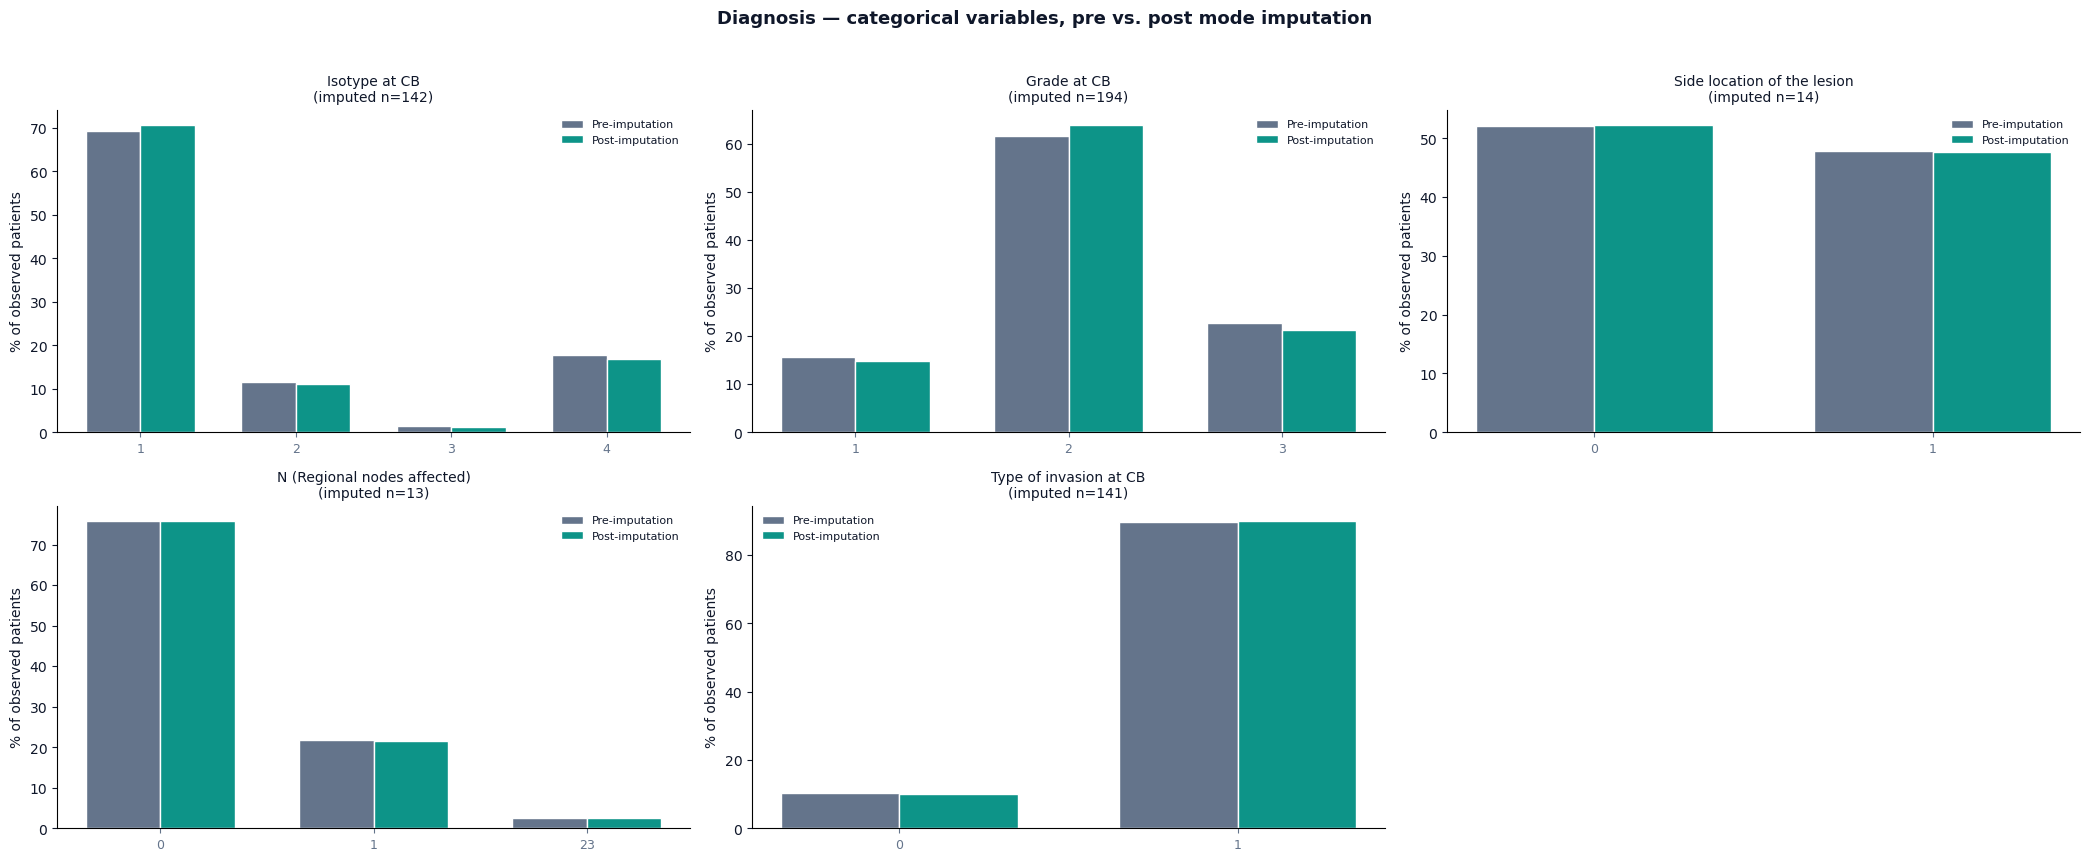

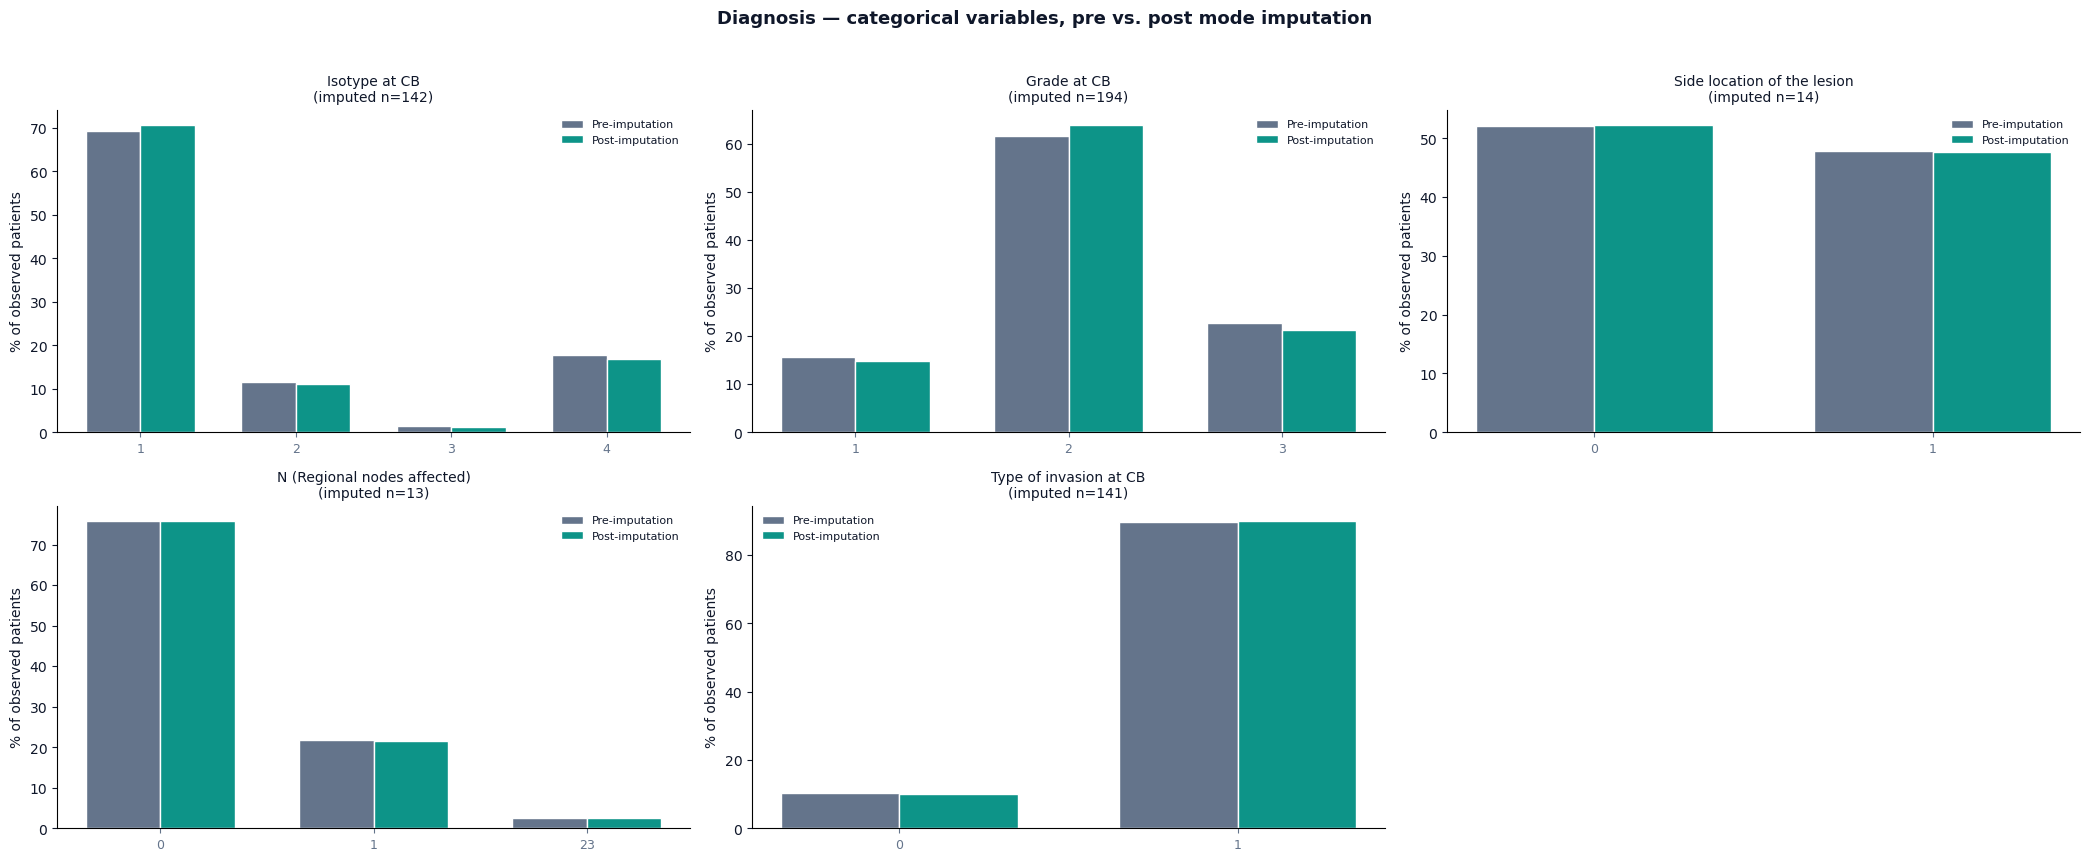

In [140]:
mode_imputed_categorical = ['Isotype at CB', 'Grade at CB', 'Side location of the lesion',
                             'N (Regional nodes affected)', 'Type of invasion at CB']
plot_categorical_pre_post(dataset, final_dataset, mode_imputed_categorical,
                           'Diagnosis — categorical variables, pre vs. post mode imputation',
                           'diagnosis_categorical_pre_post.png', cols=3)

### ER / PR / HER2 and treatment variables — post-transform only

These are **not** statistically imputed, so they're shown once, post-transform, without a pre/post framing:

- Oestrogen/Progesterone/HER2 receptor status keep missingness as its own explicit category (`one_hot_encode_with_missing_indicator`) rather than estimating a value for it.
- Treatment variables are 0-filled (`replace_missing_values(..., 0)`), i.e. missing is treated as "not administered" — a clinical assumption, not a statistical estimate.

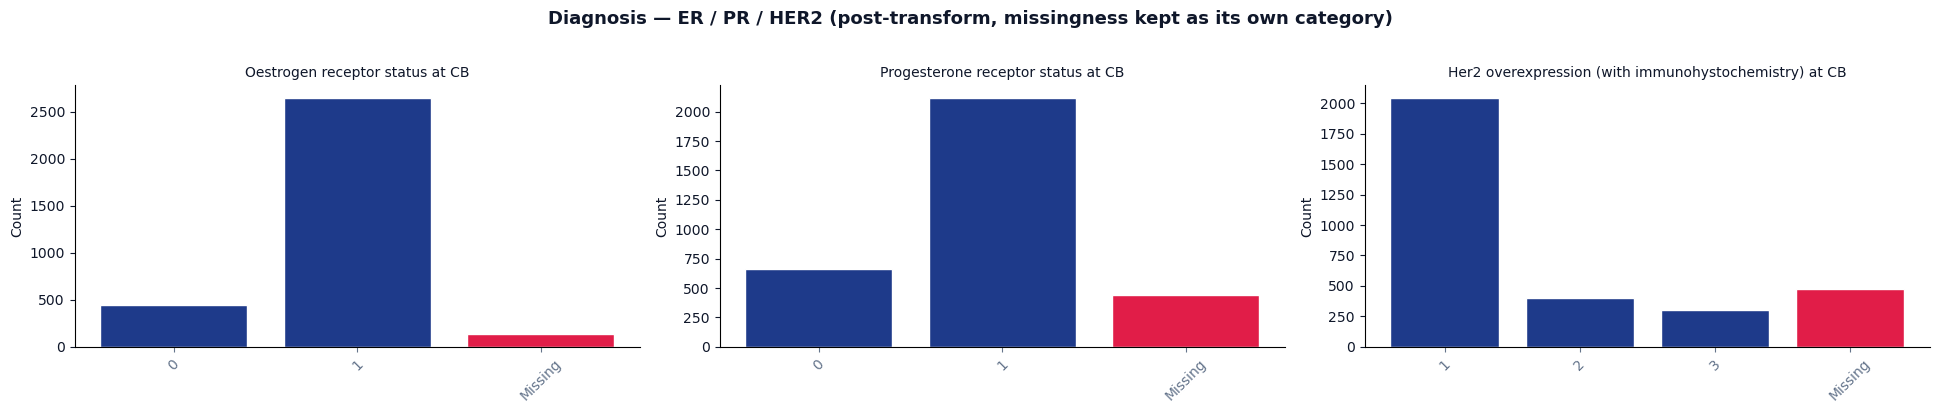

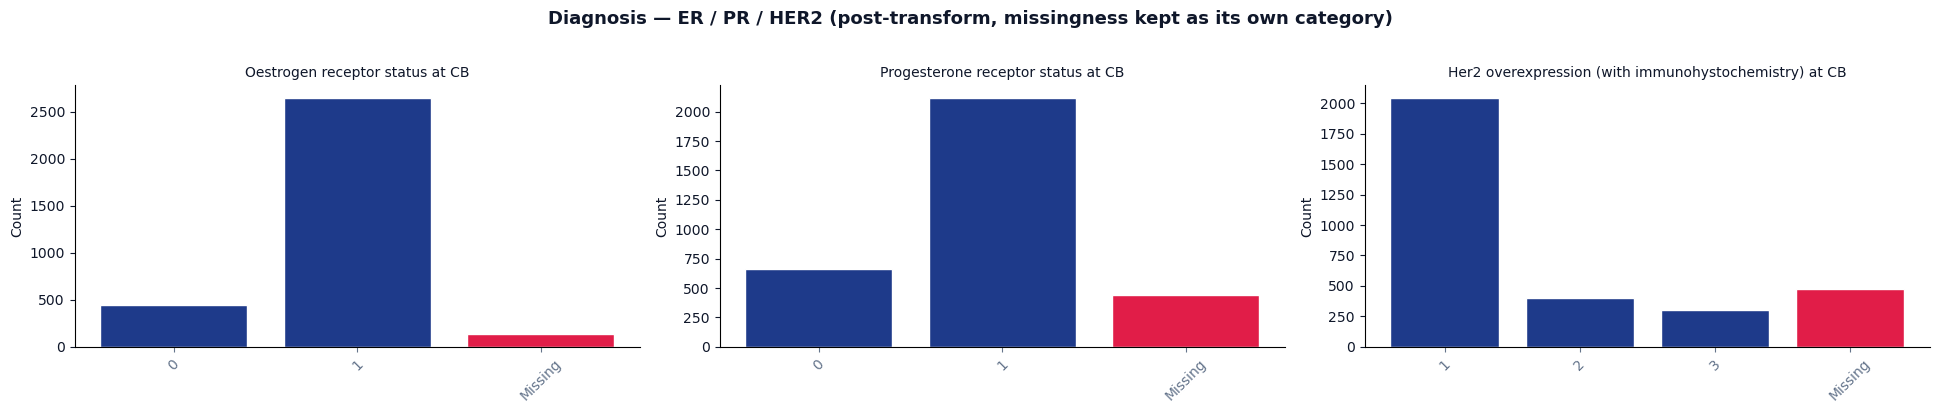

In [141]:
def plot_categorical_grid_from_series(series_dict, title, filename, cols=2):
    variables = list(series_dict.keys())
    rows = int(np.ceil(len(variables) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(6.5 * cols, 4 * rows), facecolor='none', squeeze=False)
    axes = axes.flatten()

    for ax, variable in zip(axes, variables):
        ax.set_facecolor('none')
        counts = series_dict[variable].value_counts()
        order = sort_categories(counts.index.tolist())
        counts = counts.reindex(order)
        colors = [ROSE if c == 'Missing' else NAVY for c in counts.index]
        ax.bar(counts.index, counts.values, color=colors, edgecolor='white')
        ax.set_title(variable, fontsize=10)
        ax.set_ylabel('Count')
        ax.tick_params(axis='x', rotation=45)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    for ax in axes[len(variables):]:
        ax.axis('off')

    fig.suptitle(title, fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=200, transparent=True, bbox_inches='tight')
    plt.show()
    return fig

missing_indicator_categorical = ['Oestrogen receptor status at CB', 'Progesterone receptor status at CB',
                                  'Her2 overexpression (with immunohystochemistry) at CB']
er_pr_her2_series = {v: get_post_series(final_dataset, v) for v in missing_indicator_categorical}
plot_categorical_grid_from_series(er_pr_her2_series,
                                   'Diagnosis — ER / PR / HER2 (post-transform, missingness kept as its own category)',
                                   'diagnosis_missing_indicator_post.png', cols=3)

In [142]:
# Create a derived neoadjuvant therapy only variable.
# It is 1 when adjuvant therapy with biological drugs is 0 and endocrine therapy performed is 1.
final_dataset['Neoadjuvant (Only) therapy with biological drugs'] = (
    (final_dataset['Adjuvant therapy using biological drugs'] == 0) &
    (final_dataset['Endocrine therapy performed'] == 1)
).astype(int)

treatment_final_variables = [
    col for col in treatment_final_variables
    if col != 'Endocrine therapy performed'
]
treatment_final_variables.append('Neoadjuvant (Only) therapy with biological drugs')

### Treatment variables — after preprocessing

Shown here (not in Section 3) because treatment variables only make sense fully filled: `final_dataset` already has every treatment value 0-filled ("not administered"), so there's no missingness left to report. For the numerical treatment variables, `Performed` counts patients with a non-zero value (0 = not administered), analogous to the value counts in the categorical table below.

In [143]:
treatment_final_numerical = ['Conventional RT fraction', 'Total administered dose', 'Boost dose administered']
treatment_final_categorical = [v for v in treatment_final_variables if v not in treatment_final_numerical]

display(numerical_stats_with_performed(final_dataset, treatment_final_numerical))
display(categorical_distribution_wide(final_dataset, treatment_final_categorical, include_missing=False))

,Performed,Counts,Mean,Median,Sd,Max,Min (performed),25th,50th,75th
Conventional RT fraction,2590 (80.3%),3227,2.487450,3.0,1.612705,24.0,2.0,2.0,3.0,3.0
Total administered dose,2612 (80.9%),3227,33.175085,41.0,16.531078,70.0,5.0,41.0,41.0,41.0
Boost dose administered,2318 (71.8%),3227,2.133870,3.0,1.421011,24.0,2.0,0.0,3.0,3.0


,Value 1,Value 2
Variable,,
Adjuvant therapy using biological drugs,0 (88.2%),1 (11.8%)
Trastuzumab or other drugs,0 (98.3%),1 (1.7%)
Radiotherapy (RT) performed,0 (13.0%),1 (87.0%)
Radiotherapy on chest wall,0 (12.7%),1 (87.3%)
Radiotherapy on supraclavicular area,0 (73.5%),1 (26.5%)
Radiotherapy on internal mammary chain,0 (98.0%),1 (2.0%)
State (if hormone therapy prescribed),0 (20.1%),1 (79.9%)
Treatment in association with chemotherapy,0 (61.7%),1 (38.3%)
Chemotherapy performed,0 (63.9%),1 (36.1%)


## 5. Figures for the main text

Copy these into the main body; everything else in `distributions/` is appendix material:

- `missingness_summary.png` — one chart, % missing per variable, treatment vs. diagnosis.
- `diagnosis_numerical_pre_post.png` — Ki67 (and Age) pre- vs. post-imputation, illustrating that median imputation doesn't distort the shape and connecting back to the skew/Shapiro result above.